In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from data import GDPHMM_OAR_V3
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED

In [3]:
dataset = build_dataset('test')

In [4]:
baseline_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
fp16_train_pred = ModelResults('111-mixed-precision', 'ddpm-1000', 199, 'test', dataset)
bf16_train_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
bf16_samp_pred = ModelResults('101-beamdiff', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
fp16_samp_pred = ModelResults('101-beamdiff', 'ddpm-1000-fp16-amp', 199, 'test', dataset)
bf16_bf16_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
bf16_fp16_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-fp16-amp', 199, 'test', dataset)

# Mixed Precision Training

In [28]:
training_comparison = ModelComparison(
  [baseline_pred, fp16_train_pred, bf16_train_pred],
  ['Baseline', 'FP16 AMP Training', 'BF16 AMP Training'],
)

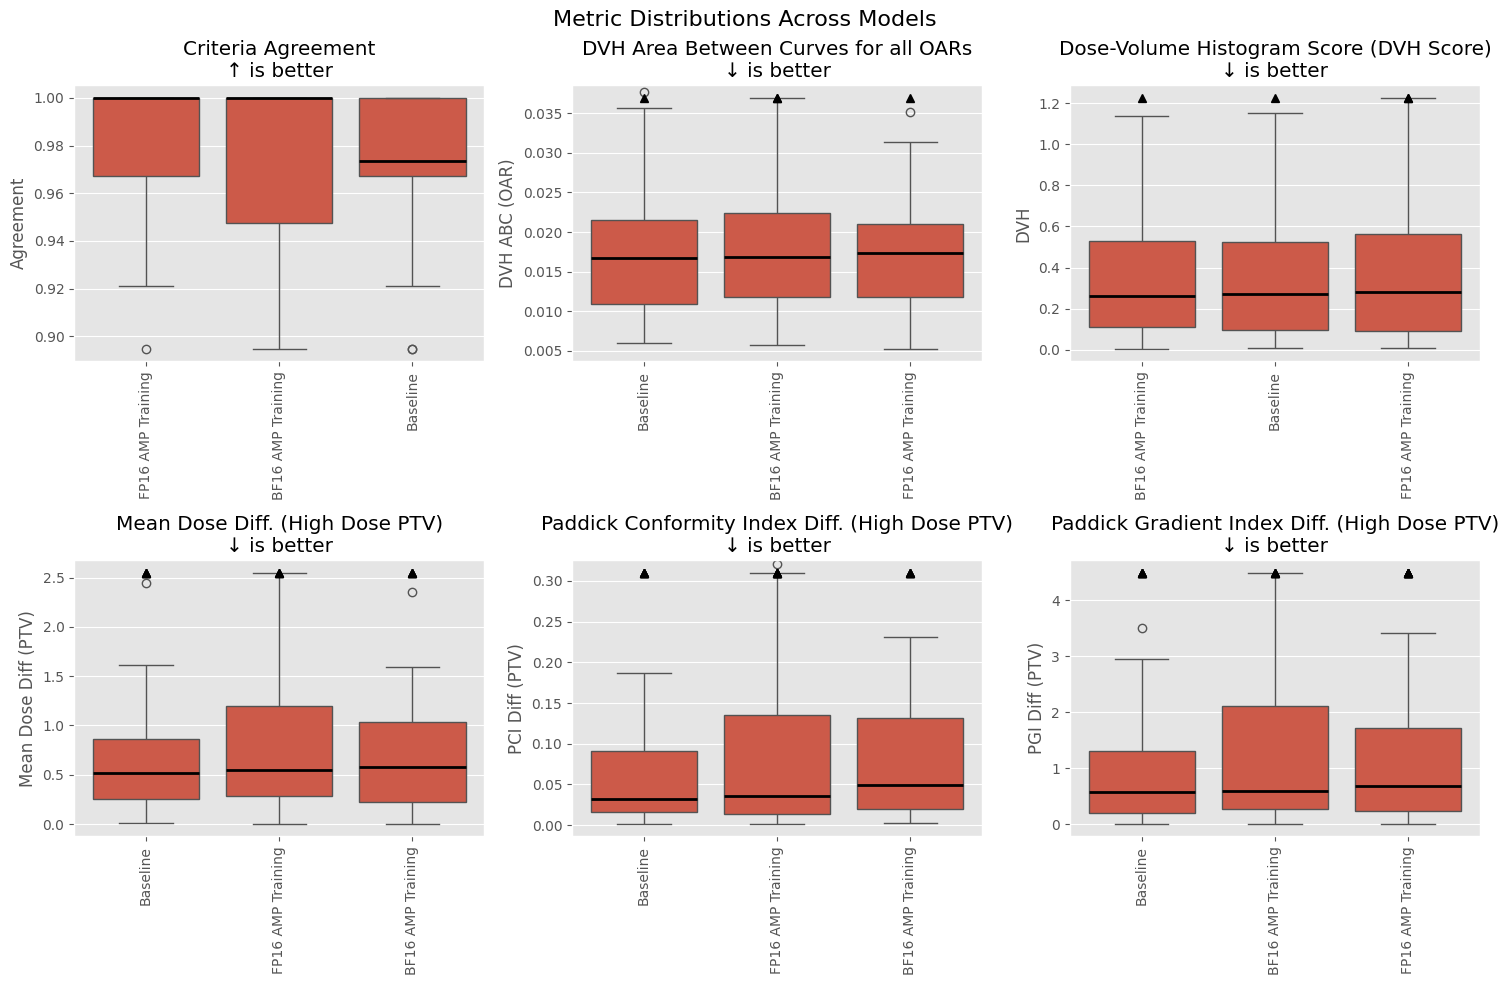

In [29]:
_ = training_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=False)

# Post-Training Quantization Sampling

In [30]:
sampling_comparison = ModelComparison(
  [baseline_pred, bf16_samp_pred, fp16_samp_pred],
  ['Baseline', 'bfloat16 Sampling', 'float16 Sampling']
)

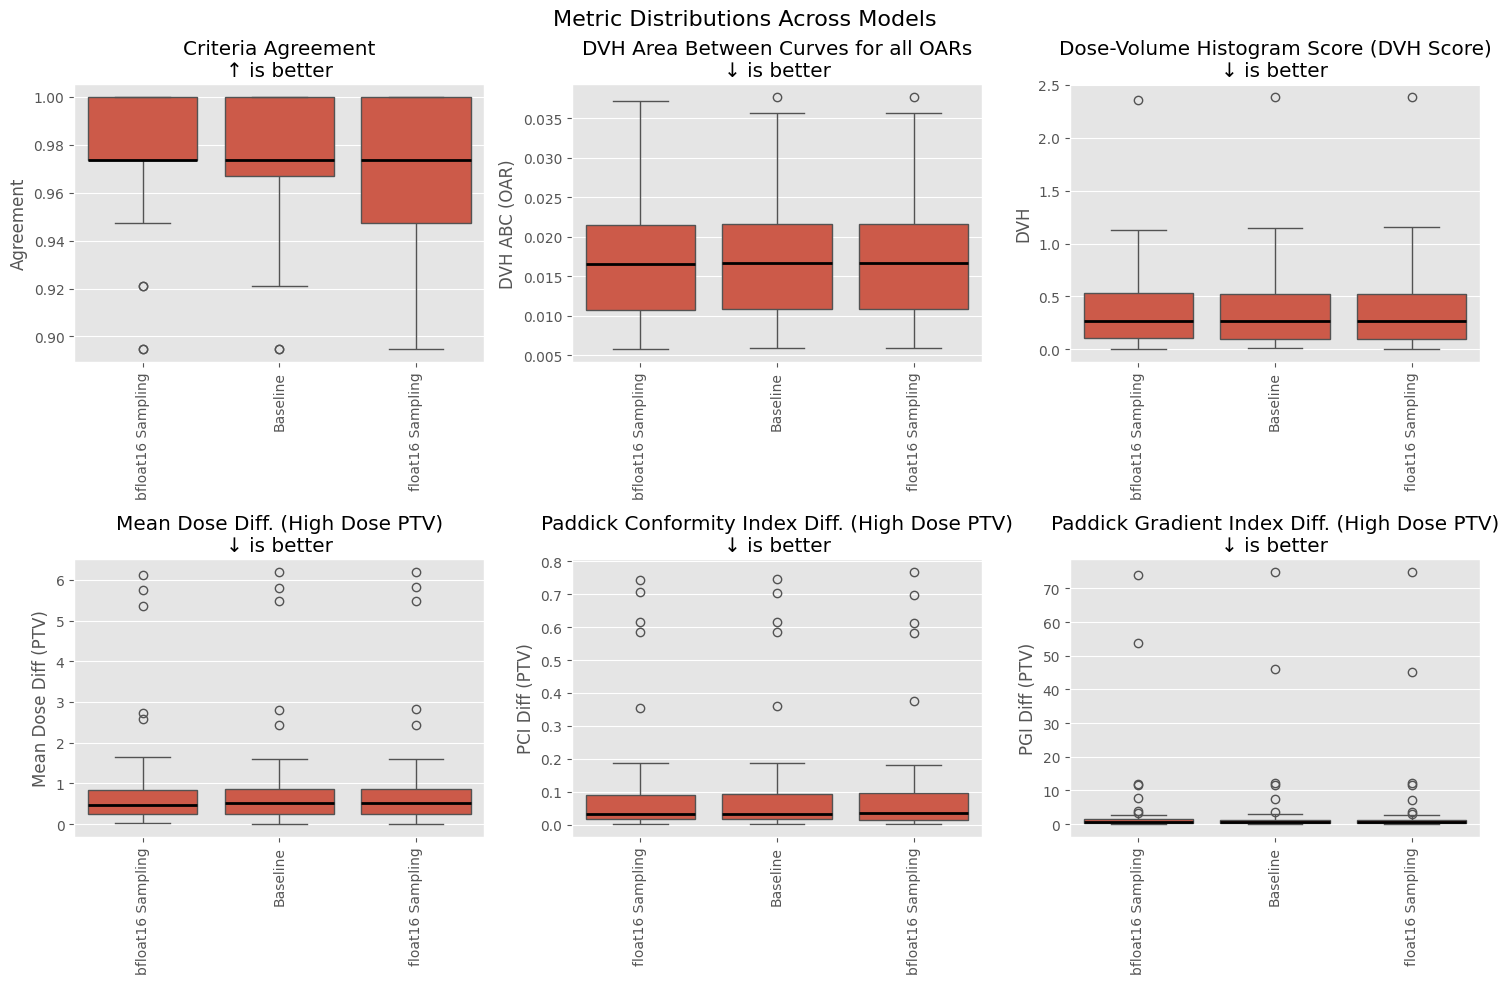

In [31]:
_ = sampling_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=True)

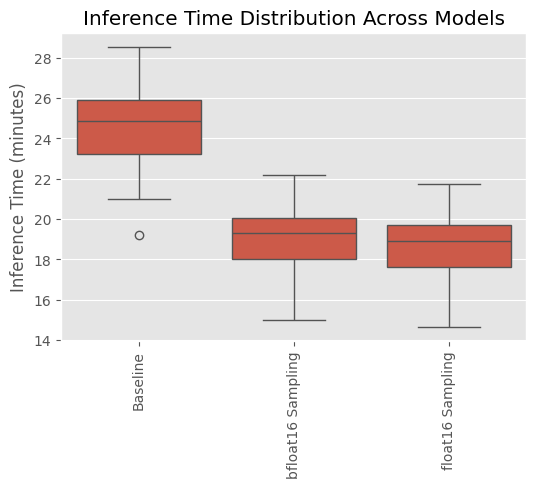

In [15]:
_ = sampling_comparison.plot_inference_times()

# AMP + Post-Training Quantization